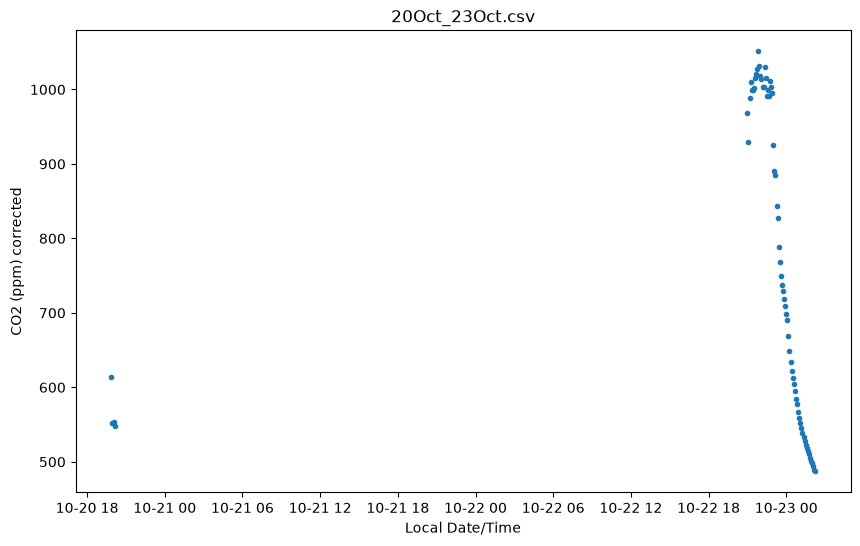

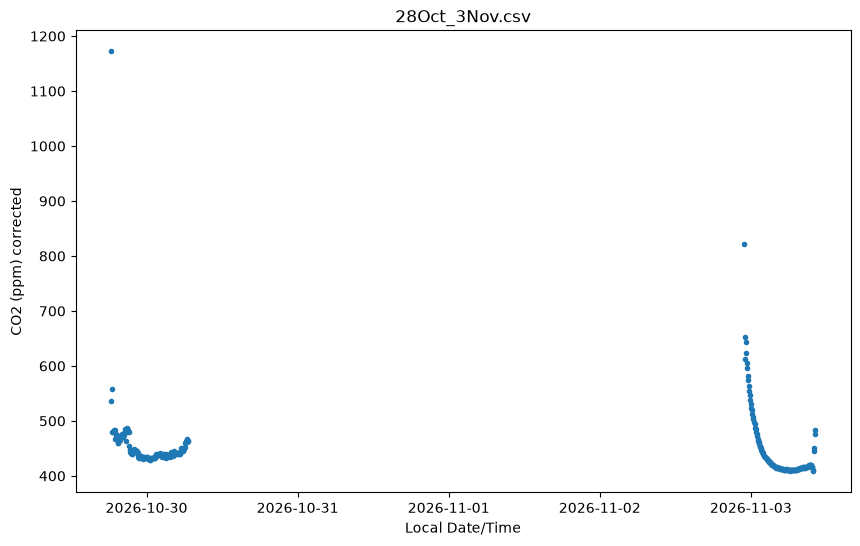

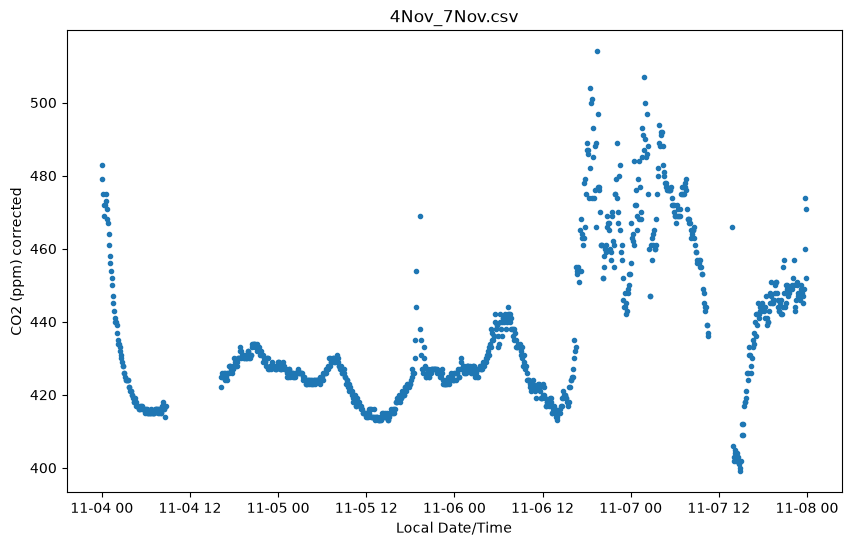

In [3]:
# visualizing data 20-23 Oct, 28-30 Oct, and 4-7 Nov
import pandas as pd
import matplotlib.pyplot as plt
# read files in a loop 
files = ['20Oct_23Oct.csv', '28Oct_3Nov.csv', '4Nov_7Nov.csv']

# figure 1 - overview 
# data: x - "Local Date/Time", y - "CO2 (ppm) corrected"
for f in files:
    data = pd.read_csv(f)
    data['Local Date/Time'] = pd.to_datetime(data['Local Date/Time']) # convert time
    plt.figure(figsize=(10, 6))
    plt.plot(data['Local Date/Time'], data['CO2 (ppm) corrected'], ".")
    plt.xlabel('Local Date/Time')
    plt.ylabel('CO2 (ppm) corrected')
    plt.title(f)
    plt.show()

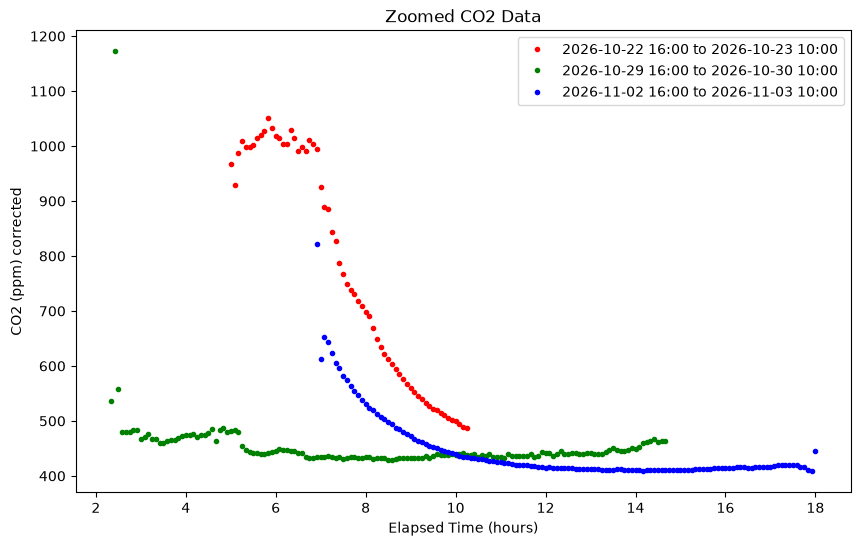

In [22]:

# figure 2 - zoom in 3 periods! 
zoom_periods = [
    ('2026-10-22 16:00', '2026-10-23 10:00'),
    ('2026-10-29 16:00', '2026-10-30 10:00'),
    ('2026-11-02 16:00', '2026-11-03 10:00'),
]
# each file should only cover the relevant zoom periods within its date range
# we want to plot the three curves in the same figure; 
# they are all 18 hour periods so we can overlay them; 
# align the starting point and ending point of each zoom period with each other; 
# use colours to show different zoom periods

colors = ['r', 'g', 'b']
plt.figure(figsize=(10, 6))
for i, (start, end) in enumerate(zoom_periods):
    for f in files:
        data = pd.read_csv(f)
        data['Local Date/Time'] = pd.to_datetime(data['Local Date/Time'])
        mask = (data['Local Date/Time'] >= start) & (data['Local Date/Time'] <= end)
        zoom_data = data.loc[mask]
        if not zoom_data.empty:
            # align the starting point to 0
            zoom_data = zoom_data.copy()
            zoom_data['Elapsed Time'] = (zoom_data['Local Date/Time'] - pd.to_datetime(start)).dt.total_seconds() / 3600
            plt.plot(zoom_data['Elapsed Time'], zoom_data['CO2 (ppm) corrected'], ".", color=colors[i], label=f'{start} to {end}')
plt.xlabel('Elapsed Time (hours)')
plt.ylabel('CO2 (ppm) corrected')
plt.title('Zoomed CO2 Data')
plt.legend()
plt.show()


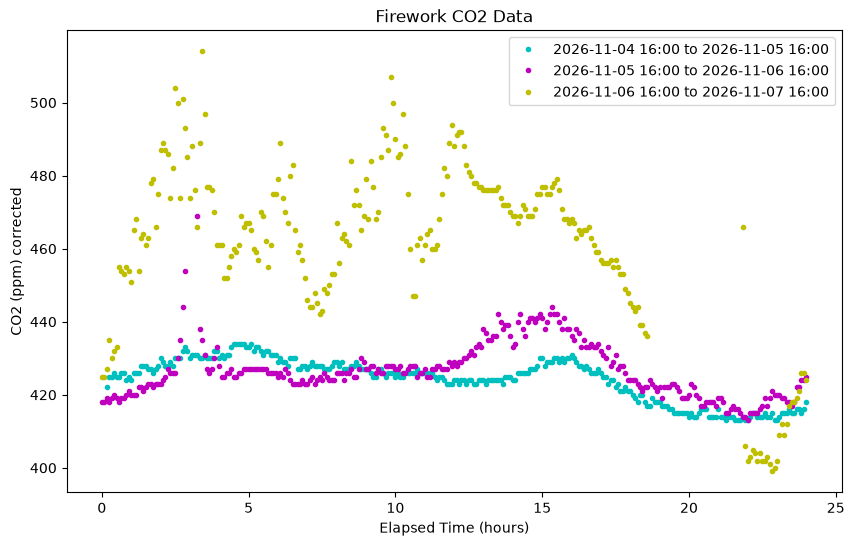

In [23]:
# figure 3 - zoom in 1-day periods for the firework data
firework_periods = [
    ('2026-11-04 16:00', '2026-11-05 16:00'),
    ('2026-11-05 16:00', '2026-11-06 16:00'),
    ('2026-11-06 16:00', '2026-11-07 16:00'),
]
# each file should only cover the relevant zoom periods within its date range
# we want to plot the three curves in the same figure; 
# they are all 18 hour periods so we can overlay them; 
# align the starting point and ending point of each zoom period with each other; 
# use colours to show different zoom periods

colors = ['c', 'm', 'y']
plt.figure(figsize=(10, 6))
for i, (start, end) in enumerate(firework_periods):
    for f in files:
        data = pd.read_csv(f)
        data['Local Date/Time'] = pd.to_datetime(data['Local Date/Time'])
        mask = (data['Local Date/Time'] >= start) & (data['Local Date/Time'] <= end)
        zoom_data = data.loc[mask]
        if not zoom_data.empty:
            # align the starting point to 0
            zoom_data = zoom_data.copy()
            zoom_data['Elapsed Time'] = (zoom_data['Local Date/Time'] - pd.to_datetime(start)).dt.total_seconds() / 3600
            plt.plot(zoom_data['Elapsed Time'], zoom_data['CO2 (ppm) corrected'], ".", color=colors[i], label=f'{start} to {end}')
plt.xlabel('Elapsed Time (hours)')
plt.ylabel('CO2 (ppm) corrected')
plt.title('Firework CO2 Data')
plt.legend()
plt.show()


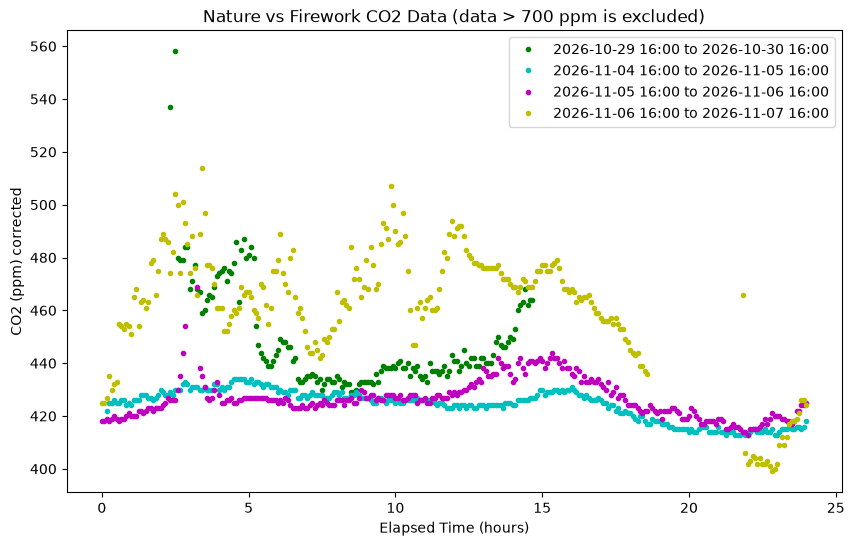

In [28]:
# fig 4 - comparing first two days of fireworks and the Astronomy date 

nature_periods = [
    ('2026-10-29 16:00', '2026-10-30 16:00'),
    ('2026-11-04 16:00', '2026-11-05 16:00'),
    ('2026-11-05 16:00', '2026-11-06 16:00'),
    ('2026-11-06 16:00', '2026-11-07 16:00'),
]


colors = ['g', 'c', 'm', 'y']
plt.figure(figsize=(10, 6))
for i, (start, end) in enumerate(nature_periods):
    for f in files:
        data = pd.read_csv(f)
        data['Local Date/Time'] = pd.to_datetime(data['Local Date/Time'])
        mask = (data['Local Date/Time'] >= start) & (data['Local Date/Time'] <= end)
        zoom_data = data.loc[mask]
        # excluding data larger than 700 ppm
        zoom_data = zoom_data[zoom_data['CO2 (ppm) corrected'] <= 700]
        if not zoom_data.empty:
            # align the starting point to 0
            zoom_data = zoom_data.copy()
            zoom_data['Elapsed Time'] = (zoom_data['Local Date/Time'] - pd.to_datetime(start)).dt.total_seconds() / 3600
            plt.plot(zoom_data['Elapsed Time'], zoom_data['CO2 (ppm) corrected'], ".", color=colors[i], label=f'{start} to {end}')
plt.xlabel('Elapsed Time (hours)')
plt.ylabel('CO2 (ppm) corrected')
plt.title('Nature vs Firework CO2 Data (data > 700 ppm is excluded)')
plt.legend()
plt.show()
